### Import Library

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix
)

### Memuat data siap pakai dari hasil Tahap 6

In [2]:
X_train, X_test, y_train, y_test = joblib.load('../dataset/step_06_ready_for_model.pkl')
print("Data berhasil dimuat! Ukuran X_train:", X_train.shape)

Data berhasil dimuat! Ukuran X_train: (3891, 12)


### Menyiapkan Kategori Harga (Murah, Sedang, Mahal)

In [3]:
# Batas kuartil diambil dari y_train (0 = Murah, 1 = Sedang, 2 = Mahal)
_, bins = pd.qcut(y_train, q=3, retbins=True, labels=[0, 1, 2])
bins[0], bins[-1] = -float('inf'), float('inf')

### Mengubah y_train dan y_test menjadi kategori kelas (0, 1, 2)

In [4]:
y_train_kelas = pd.cut(y_train, bins=bins, labels=[0, 1, 2]).astype(int)
y_test_kelas  = pd.cut(y_test, bins=bins, labels=[0, 1, 2]).astype(int)

### Mencari Parameter var_smoothing Terbaik

In [5]:
smoothing_values = np.logspace(-9, -1, 9)
acc_scores = []

for val in smoothing_values:
    nb_temp = GaussianNB(var_smoothing=val)
    nb_temp.fit(X_train, y_train_kelas)
    y_pred_temp = nb_temp.predict(X_test)
    acc_scores.append(accuracy_score(y_test_kelas, y_pred_temp))

best_smoothing = smoothing_values[np.argmax(acc_scores)]
print(f"Nilai var_smoothing terbaik adalah: {best_smoothing} dengan Accuracy: {max(acc_scores):.4f}")

Nilai var_smoothing terbaik adalah: 1e-09 dengan Accuracy: 0.6588


### Visualisasi pemilihan var_smoothing vs Accuracy

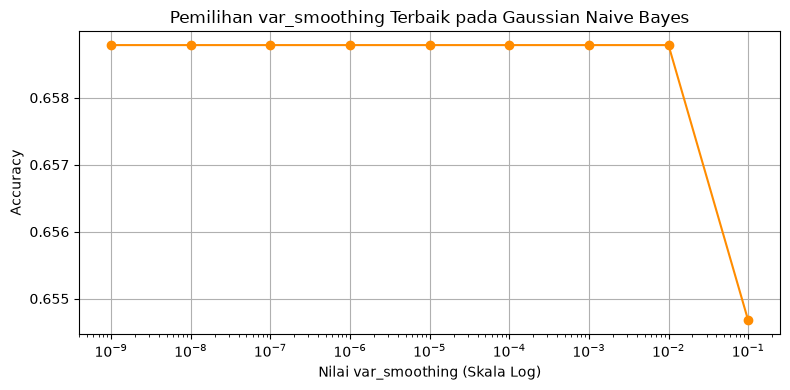

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(smoothing_values, acc_scores, marker='o', linestyle='-', color='darkorange')
plt.xscale('log')
plt.title('Pemilihan var_smoothing Terbaik pada Gaussian Naive Bayes')
plt.xlabel('Nilai var_smoothing (Skala Log)')
plt.ylabel('Accuracy')
plt.grid(True)
plt.tight_layout()
plt.show()

### Melatih Model Naive Bayes Final

In [7]:
start_time = time.perf_counter()

model_nb = GaussianNB(var_smoothing=best_smoothing)
model_nb.fit(X_train, y_train_kelas)
y_pred_nb = model_nb.predict(X_test)

end_time = time.perf_counter()

waktu_nb = end_time - start_time

print("Model Berhasil Dibuat!")
print(f"Waktu Eksekusi Model Naive Bayes: {waktu_nb:.4f} detik")

Model Berhasil Dibuat!
Waktu Eksekusi Model Naive Bayes: 0.0119 detik


### Evaluasi

In [8]:
acc_nb = accuracy_score(y_test_kelas, y_pred_nb)
prec_nb = precision_score(y_test_kelas, y_pred_nb, average='weighted')
rec_nb = recall_score(y_test_kelas, y_pred_nb, average='weighted')
f1_nb = f1_score(y_test_kelas, y_pred_nb, average='weighted')

print("=== HASIL EVALUASI MODEL NAIVE BAYES ===")
print(f"1. Accuracy       : {acc_nb:.4f} ({acc_nb*100:.2f}%)")
print(f"2. Precision      : {prec_nb:.4f}")
print(f"3. Recall         : {rec_nb:.4f}")
print(f"4. F1-Score       : {f1_nb:.4f}")
print(f"5. Waktu Eksekusi : {waktu_nb:.4f} detik")

=== HASIL EVALUASI MODEL NAIVE BAYES ===
1. Accuracy       : 0.6588 (65.88%)
2. Precision      : 0.6647
3. Recall         : 0.6588
4. F1-Score       : 0.6604
5. Waktu Eksekusi : 0.0119 detik


### Visualisasi Confusion Matrix

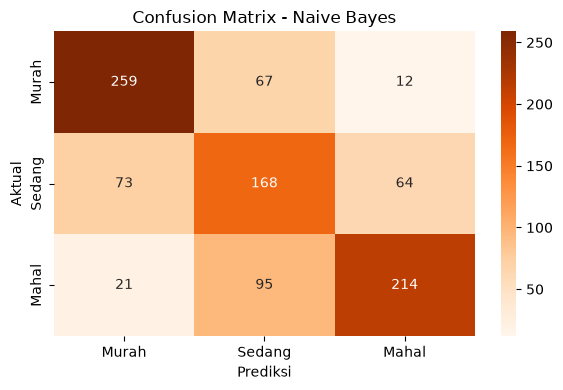

In [9]:
cm_nb = confusion_matrix(y_test_kelas, y_pred_nb)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=['Murah', 'Sedang', 'Mahal'], 
            yticklabels=['Murah', 'Sedang', 'Mahal'])
plt.title('Confusion Matrix - Naive Bayes')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

### Menyimpan Hasil Naive Bayes

In [10]:
hasil_nb = {
    'Model': 'Naive Bayes',
    'Accuracy': acc_nb,
    'Precision': prec_nb,
    'Recall': rec_nb,
    'F1-Score': f1_nb,
    'Waktu (Detik)': waktu_nb,
    'y_test_kelas': y_test_kelas,
    'y_pred_kelas': y_pred_nb
}

joblib.dump(hasil_nb, 'hasil_nb.pkl')
print("Hasil evaluasi Naive Bayes berhasil disimpan ke 'klasifikasi_model/hasil_nb.pkl'!")

Hasil evaluasi Naive Bayes berhasil disimpan ke 'klasifikasi_model/hasil_nb.pkl'!
